# 2D array: first simulation

Start here for the 2D model. Geometry 5 is bundled with the repository. Run cells from top to bottom: load geometry, choose physical parameters, propagate, inspect mode fidelity and probability snapshots. This runs one full simulation, not a parameter sweep.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


<h1>2D Fiber Scattering Example</h1>

Load a saved matter-interface geometry, then run a one-photon scattering experiment.

In [3]:
SAVE_FIGURES = False  # Set True to export the figures to results/fig.



# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

import numpy as np

resol = 200
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "mathtext.fontset": "cm",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})


from src import Experiment
from importlib import import_module
load_geometry_by_id = import_module("2d_setup.geometry").load_geometry_by_id
make_2d_config = import_module("2d_setup.setup").make_2d_config

pi = np.pi

<h2>Load matter geometry</h2>

In [2]:
geometry_id = 5
geometry = load_geometry_by_id(geometry_id)

L1, L2 = geometry["lengths"]
N_A = geometry["N_A"]
atom_positions = geometry["atom_positions"]

print(f"Loaded geometry: {geometry['path'].name}")
print(f"lengths={geometry['lengths']}, N_A={N_A}, N_layer={geometry['N_layer']}, kind={geometry['kind']}")

Loaded geometry: geometry_id5.csv
lengths=[5. 5.], N_A=10, N_layer=1, kind=slab


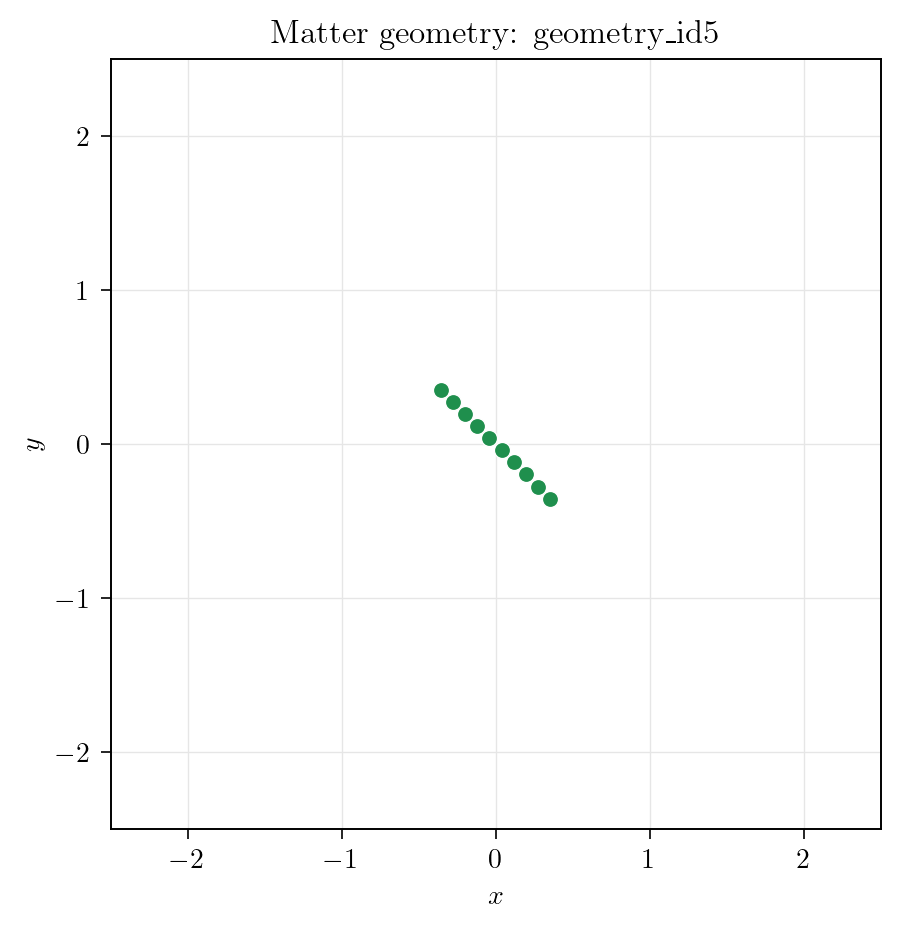

In [4]:
from src.plot_fonts import paper_fonts

fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
ax.scatter(
    atom_positions[:, 0],
    atom_positions[:, 1],
    s=34,
    color="#1f8f4d",
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)
ax.set_xlim(-L1 / 2, L1 / 2)
ax.set_ylim(-L2 / 2, L2 / 2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.grid(color="0.9", linewidth=0.5)
latex_label = geometry["label"].replace("_", r"\_")
ax.set_title(f"Matter geometry: {latex_label}")
# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 13)
plt.show()

<h2>Experiment parameters</h2>

In [5]:
Omega_A_tab = 10 * np.pi * np.ones(N_A)
d_A_tab = np.ones(N_A, dtype=float)

omega_init = 10 * np.pi
param_photon = {
    "p_init": [omega_init, 0.0],
    "sigma_p": [np.pi, np.pi],
    "x_init": [-L1 / 4, 0.0],
}

param_time_evol = {"T": L1 / 2, "dt": 0.01}
cutoffs = {"Omega_min": 0 * np.pi, "Omega_max": 20 * np.pi}
use_correction = False

param_atom = {
    "Omega_A": Omega_A_tab,
    "d_A": d_A_tab,
    "geometry": geometry,
}

config = make_2d_config(
    param_photon=param_photon,
    param_atom=param_atom,
    param_time_evol=param_time_evol,
    cutoffs=cutoffs,
    correction=use_correction,
)

scattering_experiment = Experiment(config)

print(f"Config dimension: {config.p_n.shape[1]}")
print(f"Config atom count: {scattering_experiment.n_atoms}")
print(f"Target Omega_A/pi: {Omega_A_tab[0] / np.pi:.6f}")
print(f"Target d_A: {d_A_tab[0]:.6f}")
print(f"Correction enabled: {use_correction}")

Config dimension: 2
Config atom count: 10
Target Omega_A/pi: 10.000000
Target d_A: 1.000000
Correction enabled: False


<h2>Run the propagation</h2>

In [6]:
c_array, b_array = scattering_experiment.propagate_state(progress=True)
messages = scattering_experiment.get_messages()

time_array = scattering_experiment.times
observables = scattering_experiment.compute_observables()
An_array = observables.atomic_population
mode_fidelity = observables.mode_fidelity
orthogonal_population = observables.orthogonal_photon_population
forward_array = scattering_experiment.observables.forward
backward_array = scattering_experiment.observables.backward
side_array = scattering_experiment.observables.side
total_array = mode_fidelity + orthogonal_population + An_array

print(f"Final orthogonal photon population: {orthogonal_population[-1]:.6f}")
print(f"Final mode fidelity: {mode_fidelity[-1]:.6f}")
print(f"Final atomic excitation: {An_array[-1]:.6f}")
print(f"Final total probability: {total_array[-1]:.12f}")

  0%|          | 0/250 [00:00<?, ?it/s]

Final orthogonal photon population: 0.624047
Final mode fidelity: 0.375886
Final atomic excitation: 0.000066
Final total probability: 1.000000037923


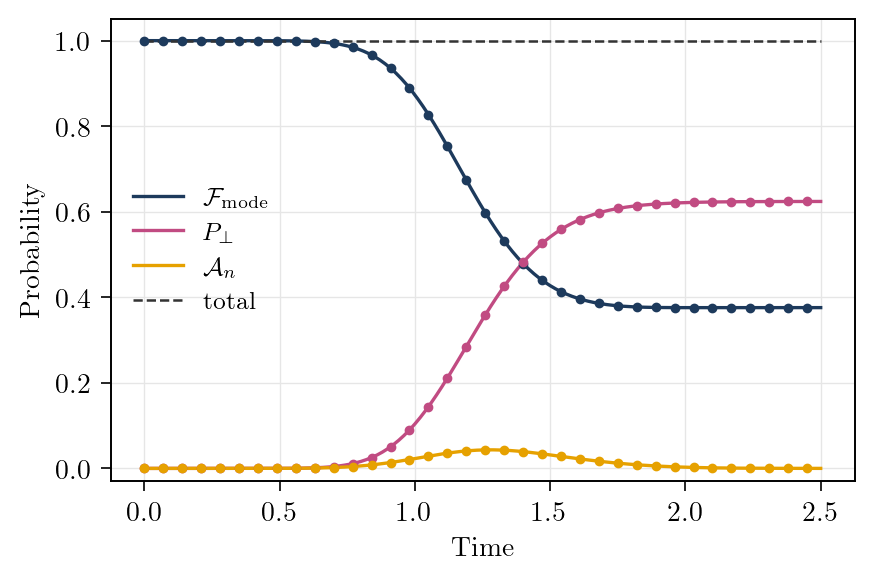

In [7]:
from src.plot_fonts import paper_fonts

fig, ax = plt.subplots(figsize=(4.8, 3.0), dpi=resol)

step_marker = max(1, len(time_array) // 35)
color_Tn = "#1d3a5c"
color_Rn = "#c14b82"
color_atom = "#e6a100"

ax.plot(time_array, mode_fidelity, color=color_Tn, lw=1.2, label=r"$\mathcal{F}_{\mathrm{mode}}$")
ax.plot(time_array, orthogonal_population, color=color_Rn, lw=1.2, label=r"$P_{\perp}$")
ax.plot(time_array, An_array, color=color_atom, lw=1.2, label=r"$\mathcal{A}_n$")
ax.plot(time_array, total_array, color="0.2", lw=0.9, ls="--", label=r"$\mathrm{total}$")

ax.plot(time_array[::step_marker], mode_fidelity[::step_marker], "o", ms=2.5, color=color_Tn)
ax.plot(time_array[::step_marker], orthogonal_population[::step_marker], "o", ms=2.5, color=color_Rn)
ax.plot(time_array[::step_marker], An_array[::step_marker], "o", ms=2.5, color=color_atom)

ax.set_xlabel(r"$\mathrm{Time}$")
ax.set_ylabel(r"$\mathrm{Probability}$")
ax.set_ylim(-0.03, 1.05)
ax.grid(color="0.9", linewidth=0.5)
ax.legend(frameon=False, fontsize=9)
# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 12.5)
plt.show()

<h2>Photon distribution</h2>

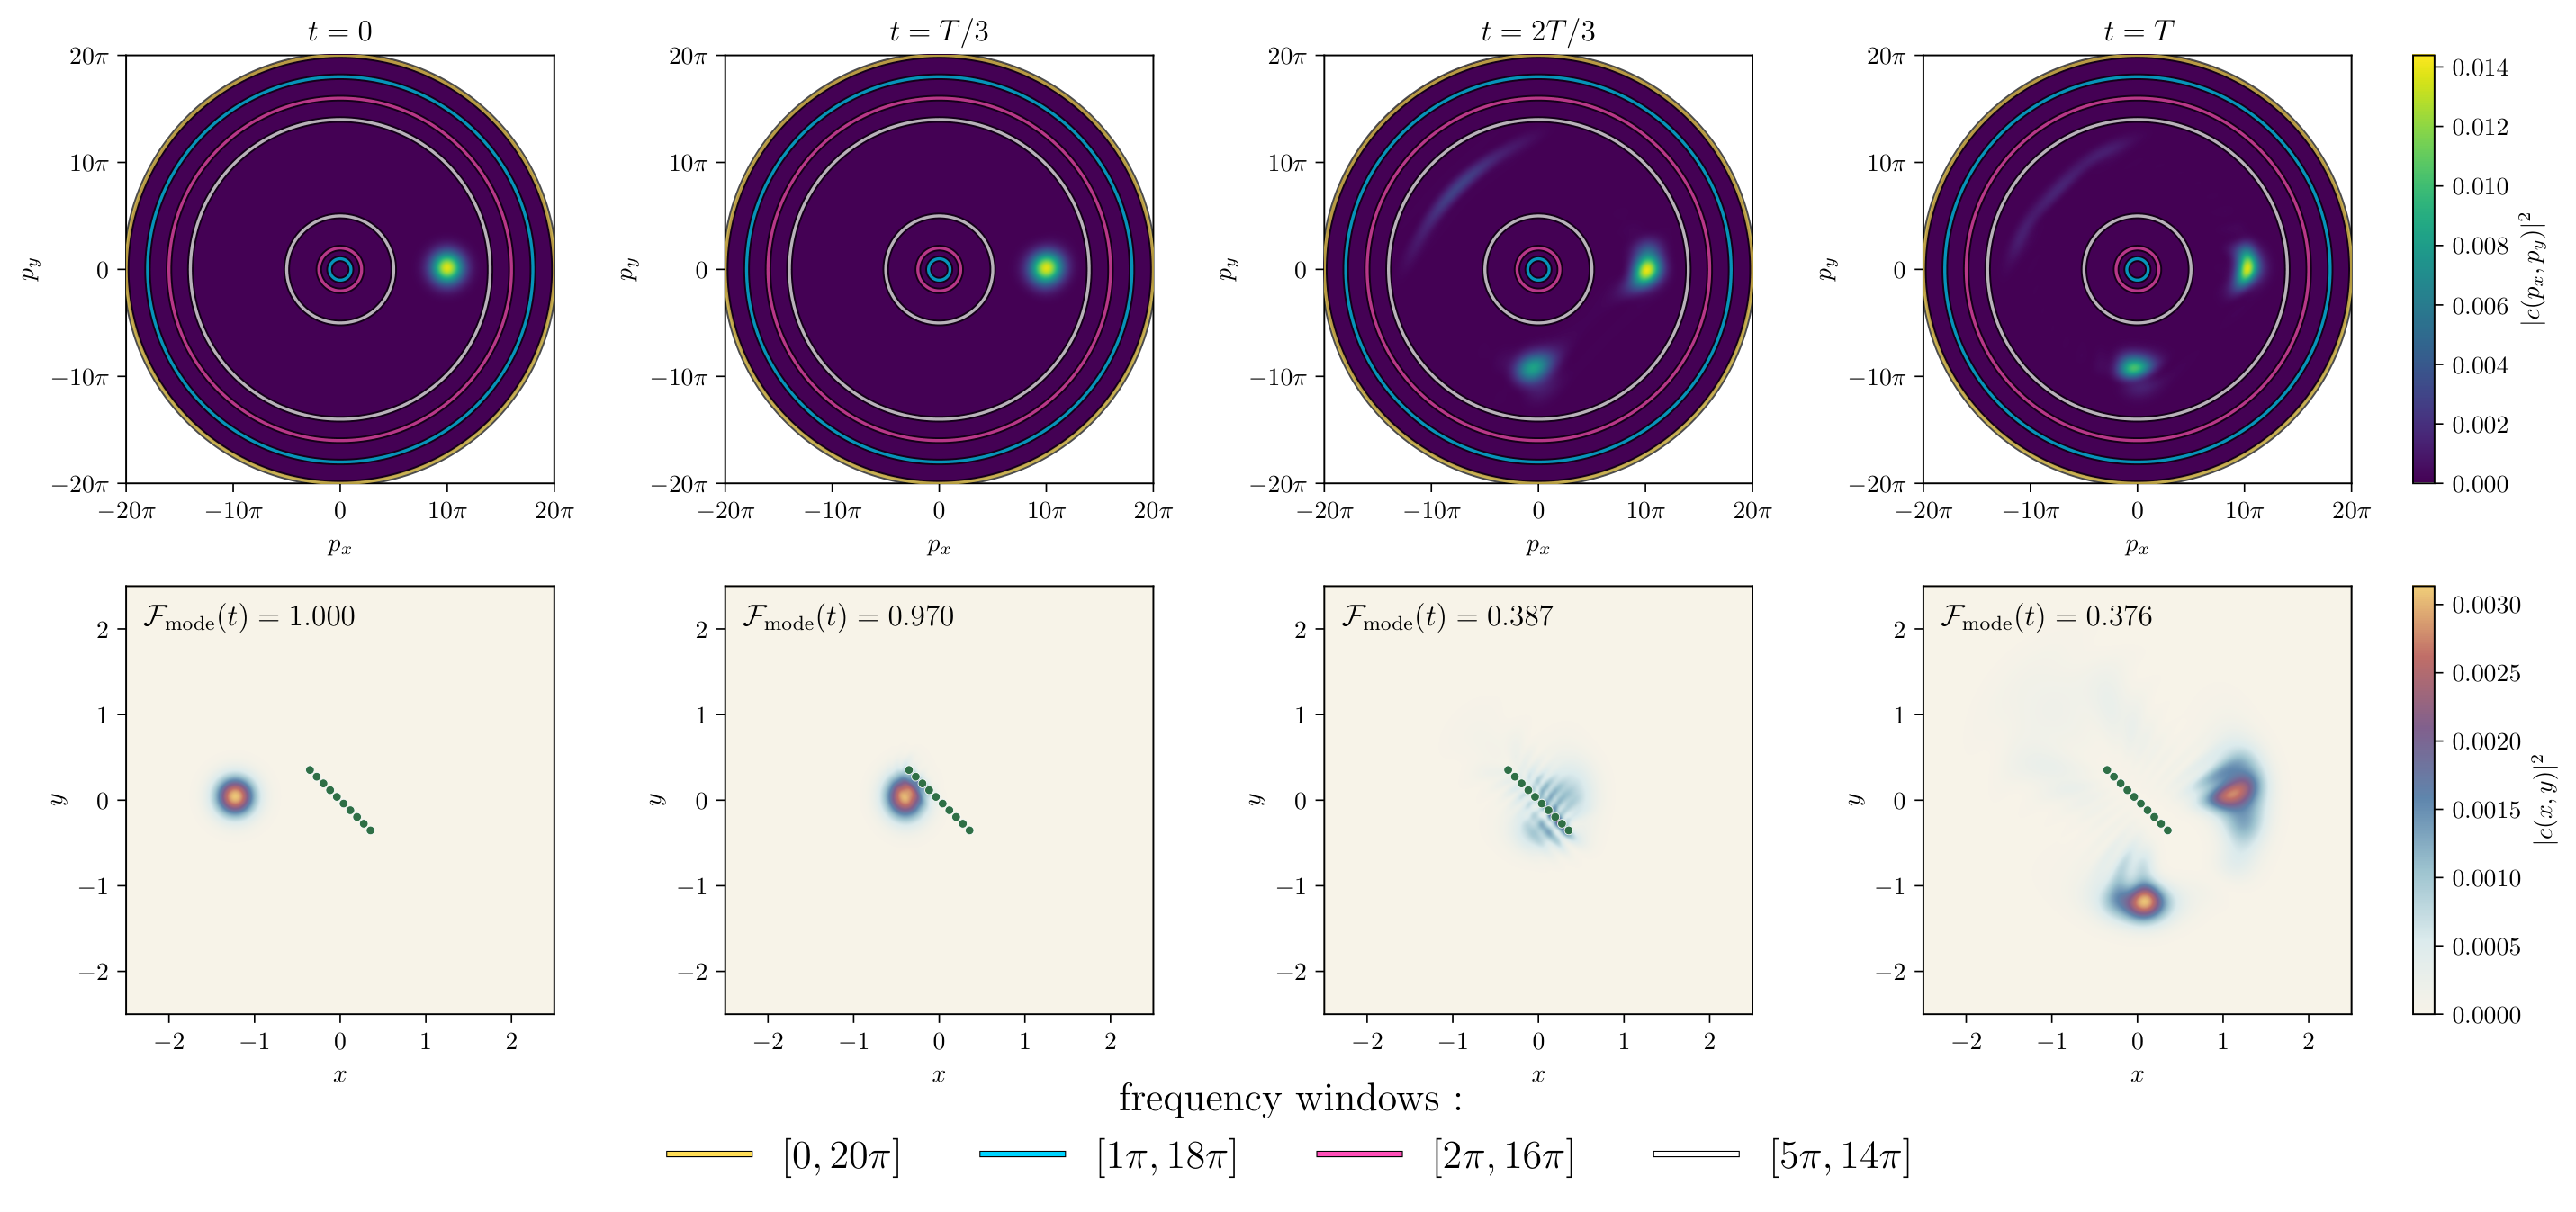

In [8]:
from src.plot_fonts import paper_fonts

# Direct discrete probability transform: readable version.
snapshot_fractions = [0, 1 / 3, 2 / 3, 1]
snapshot_labels = [r"$t=0$", r"$t=T/3$", r"$t=2T/3$", r"$t=T$"]
snapshot_indices = [
    int(np.argmin(np.abs(scattering_experiment.times - fraction * scattering_experiment.times[-1])))
    for fraction in snapshot_fractions
]
frequency_windows = [
    (0 * np.pi, 20 * np.pi, "#ffdd57", "-"),
    (1 * np.pi, 18 * np.pi, "#00d4ff", "-"),
    (2 * np.pi, 16 * np.pi, "#ff4fb8", "-"),
    (5 * np.pi, 14 * np.pi, "#ffffff", "-"),
]
plot_interpolation = "bicubic"
outer_frequency_limit = max(outer for _, outer, _, _ in frequency_windows)
momentum_ticks = np.array([-20, -10, 0, 10, 20]) * np.pi
momentum_tick_labels = [r"$-20\pi$", r"$-10\pi$", r"$0$", r"$10\pi$", r"$20\pi$"]

n_abs_max = np.max(np.abs(scattering_experiment.mode_indices), axis=0)
position_shape = tuple((2 * n_abs_max + 1).astype(int))
n_position_points = np.prod(position_shape)
x = np.linspace(-L1 / 2, L1 / 2, position_shape[0], endpoint=False)
y = np.linspace(-L2 / 2, L2 / 2, position_shape[1], endpoint=False)
x_grid, y_grid = np.meshgrid(x, y, indexing="xy")
position_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))


def compute_position_probability(c_p, t, chunk_size=512):
    c_t = c_p * np.exp(-1j * scattering_experiment.omega_n * t)
    c_pos = np.empty(len(position_points), dtype=complex)
    for start in range(0, len(position_points), chunk_size):
        stop = min(start + chunk_size, len(position_points))
        phase = np.exp(1j * position_points[start:stop] @ scattering_experiment.p_n.T)
        c_pos[start:stop] = phase @ c_t / np.sqrt(n_position_points)
    return np.abs(c_pos.reshape(position_shape[1], position_shape[0])) ** 2

mode_ix, mode_iy = (scattering_experiment.mode_indices + n_abs_max).T
dp = 2 * np.pi / scattering_experiment.lengths
n_x = np.arange(-n_abs_max[0], n_abs_max[0] + 1)
n_y = np.arange(-n_abs_max[1], n_abs_max[1] + 1)
px_grid, py_grid = np.meshgrid(n_x * dp[0], n_y * dp[1], indexing="xy")
p_extent = [(n_x[0] - 0.5) * dp[0], (n_x[-1] + 0.5) * dp[0], (n_y[0] - 0.5) * dp[1], (n_y[-1] + 0.5) * dp[1]]
x_extent = [-L1 / 2, L1 / 2, -L2 / 2, L2 / 2]

momentum_probabilities = []
position_probabilities = []
for time_index in snapshot_indices:
    p_prob = np.full((len(n_y), len(n_x)), np.nan)
    p_prob[mode_iy, mode_ix] = np.abs(scattering_experiment.c_array[time_index]) ** 2
    momentum_probabilities.append(p_prob)
    position_probabilities.append(compute_position_probability(scattering_experiment.c_array[time_index], scattering_experiment.times[time_index]))

momentum_cmap = plt.get_cmap("viridis").copy()
momentum_cmap.set_bad("white")
if "soft_density_cmap" not in globals():
    soft_density_cmap = LinearSegmentedColormap.from_list(
        "soft_density",
        ["#f7f3e8", "#dcebed", "#9dc3cf", "#5f86ad", "#81608d", "#c06e68", "#f1cf79"],
    )
position_cmap = soft_density_cmap
window_path_effects = [pe.Stroke(linewidth=2.6, foreground="black"), pe.Normal()]
frequency_window_handles = []
for inner, outer, color, linestyle in frequency_windows:
    inner_n = int(np.round(inner / np.pi))
    outer_n = int(np.round(outer / np.pi))
    inner_label = "0" if inner_n == 0 else rf"{inner_n}\pi"
    outer_label = "0" if outer_n == 0 else rf"{outer_n}\pi"
    frequency_window_handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            ls=linestyle,
            lw=1.8,
            label=rf"$[{inner_label},{outer_label}]$",
            path_effects=window_path_effects,
        )
    )

fig, axes = plt.subplots(2, len(snapshot_indices), figsize=(16, 7.4), dpi=resol)

for col, (time_label, p_prob, x_prob) in enumerate(zip(snapshot_labels, momentum_probabilities, position_probabilities)):
    p_prob_display = np.nan_to_num(p_prob, nan=0.0)
    momentum_image = axes[0, col].imshow(p_prob_display, origin="lower", extent=p_extent, cmap=momentum_cmap, interpolation=plot_interpolation, aspect="equal", rasterized=True)
    momentum_image.set_clip_path(Circle((0, 0), outer_frequency_limit, transform=axes[0, col].transData))
    position_image = axes[1, col].imshow(x_prob, origin="lower", extent=x_extent, cmap=position_cmap, interpolation=plot_interpolation, aspect="equal", rasterized=True)
    axes[0, col].set_title(time_label)
    axes[0, col].set(xlabel=r"$p_x$", ylabel=r"$p_y$", xlim=(-outer_frequency_limit, outer_frequency_limit), ylim=(-outer_frequency_limit, outer_frequency_limit))
    axes[0, col].set_xticks(momentum_ticks)
    axes[0, col].set_yticks(momentum_ticks)
    axes[0, col].set_xticklabels(momentum_tick_labels)
    axes[0, col].set_yticklabels(momentum_tick_labels)
    axes[1, col].set(xlabel=r"$x$", ylabel=r"$y$", xlim=(-L1 / 2, L1 / 2), ylim=(-L2 / 2, L2 / 2))
    axes[1, col].scatter(atom_positions[:, 0], atom_positions[:, 1], s=12, color="#2f6f46", edgecolor="white", linewidth=0.3)
    axes[1, col].text(
        0.04, 0.96,
        rf"$\mathcal{{F}}_{{\mathrm{{mode}}}}(t) = {mode_fidelity[snapshot_indices[col]]:.3f}$",
        transform=axes[1, col].transAxes, ha="left", va="top", fontsize=12,
    )

    for inner, outer, color, linestyle in frequency_windows:
        for radius in (inner, outer):
            circle = Circle((0, 0), radius, fill=False, color=color, ls=linestyle, lw=1.2, alpha=0.7, zorder=4)
            circle.set_path_effects(window_path_effects)
            axes[0, col].add_patch(circle)

fig.subplots_adjust(left=0.055, right=0.91, bottom=0.18, top=0.90, wspace=0.10, hspace=0.24)
fig.colorbar(momentum_image, ax=axes[0, :].tolist(), pad=0.025, fraction=0.024).set_label(r"$|c(p_x,p_y)|^2$")
fig.colorbar(position_image, ax=axes[1, :].tolist(), pad=0.025, fraction=0.024).set_label(r"$|c(x,y)|^2$")
fig.legend(handles=frequency_window_handles, title="frequency windows :", loc="lower center", ncol=len(frequency_windows), frameon=False, fontsize=16, title_fontsize=16, bbox_to_anchor=(0.5, 0.03))

# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 18, tick_size=16, label_size=16, legend_size=16)
if SAVE_FIGURES:
    plt.savefig(
        str(setup_root / "results" / "fig" / "density_snapshots_2d.pdf"),
        dpi=resol,
        bbox_inches="tight",
    )
plt.show()

momentum_sums = [float(np.nansum(p_prob)) for p_prob in momentum_probabilities]
position_sums = [float(np.sum(x_prob)) for x_prob in position_probabilities]
momentum_max = [float(np.nanmax(p_prob)) for p_prob in momentum_probabilities]
position_max = [float(np.max(x_prob)) for x_prob in position_probabilities]
#print("Momentum probability sums:", momentum_sums)
#print("Position probability sums:", position_sums)
#print("Momentum probability max:", momentum_max)
#print("Position probability max:", position_max)